# Credit Risk Modelling: PD, Model Validation, Stress Testing, dan Expected Loss

Notebook ini membahas proses pemodelan risiko kredit, mulai dari memperkirakan probabilitas gagal bayar nasabah (*Probability of Default* atau PD), mengevaluasi kinerja model, hingga menghitung estimasi kerugian yang diharapkan (*Expected Loss* atau EL) dalam beberapa skenario stres.

**Dataset:** German Credit (OpenML ID: 31), yang terdiri atas 1.000 data nasabah dengan 20 atribut. Setiap nasabah dikategorikan ke dalam dua kelas, yaitu *good credit* dan *bad credit*.

**Tahapan pengerjaan:**
1. Memeriksa dan memahami karakteristik data.
2. Membersihkan data dan menentukan variabel target.
3. Membagi data menjadi training set dan testing set.
4. Membangun model untuk mengestimasi PD.
5. Mengevaluasi kinerja model dan menguji kalibrasi probabilitas.
6. Melakukan stress testing untuk melihat perubahan estimasi risiko.
7. Menghitung Expected Loss dan membahas hasil analisis.

### Catatan sebelum membaca hasil

- **Dataset:** Data German Credit berasal dari tahun 1990-an dan menggunakan mata uang Deutsche Mark (DM). Dataset ini digunakan karena tersedia secara terbuka dan cukup representatif untuk mempelajari dasar pemodelan risiko kredit. Namun, karakteristiknya belum tentu mencerminkan kondisi pasar kredit saat ini.
- **Default rate:** Sebanyak 30% nasabah dalam dataset masuk kategori *bad credit*. Proporsi ini relatif tinggi dibandingkan dengan portofolio kredit perbankan pada umumnya. Oleh karena itu, hasil perhitungan kerugian dalam notebook ini tidak dapat langsung digunakan untuk menggambarkan kondisi perbankan aktual.
- **Stress testing:** Skenario stres disusun berdasarkan asumsi untuk melihat bagaimana perubahan tingkat risiko memengaruhi estimasi kerugian. Dataset tidak menyediakan variabel makroekonomi, sehingga skenario yang digunakan bukan merupakan prediksi kondisi ekonomi.

**Catatan reproduksibilitas:** Angka yang dicantumkan dalam interpretasi hasil mengacu pada satu kali eksekusi dengan `RANDOM_STATE = 42`. Hasil dapat berubah apabila parameter, pembagian data, atau konfigurasi model diubah. Jika terdapat perubahan pada kode, bagian interpretasi juga perlu disesuaikan.

## Alur Pengolahan Data

Bagian ini menjelaskan tahapan pengolahan data yang dilakukan dalam notebook, mulai dari pengambilan dataset hingga perhitungan Expected Loss. Setiap tahap memiliki perubahan bentuk data dan tujuan yang berbeda. Untuk memudahkan pemahaman, berikut ringkasan perubahan data pada setiap tahap.

| Tahap | Sebelum | Sesudah | Tujuan |
|---|---|---|---|
| 1. Pengambilan data | - | Dataset mentah dengan 1.000 baris dan 21 kolom | Menggunakan dataset publik German Credit sebagai dasar analisis. |
| 2. Transformasi target | Kolom `class` berisi kategori `good` dan `bad` | Kolom `default` dengan nilai 0 dan 1; kolom `class` dihapus | Mengubah target kategorikal menjadi numerik agar dapat digunakan dalam pemodelan. Kolom `class` tidak lagi digunakan sebagai fitur karena menjadi dasar pembentukan target. |
| 3. Pemisahan fitur dan target | Dataset dengan 1.000 baris dan 21 kolom | `X` berukuran 1.000 × 20 dan `y` berukuran 1.000 | Memisahkan variabel prediktor (`X`) dari variabel target (`y`) yang akan diprediksi oleh model. |
| 4. Pembagian data | 1.000 pinjaman | 800 pinjaman untuk training dan 200 pinjaman untuk testing | Memisahkan data untuk proses pelatihan dan evaluasi agar kinerja model dapat diuji pada data yang belum pernah digunakan selama pelatihan. |
| 5. Preprocessing | `X_train` dengan 800 baris dan 20 kolom, terdiri atas data numerik dan kategorikal | Matriks numerik hasil transformasi dengan 800 baris dan sejumlah kolom hasil encoding | Mengubah data kategorikal menjadi numerik dan melakukan scaling pada fitur numerik agar perbedaan skala tidak memengaruhi proses pemodelan secara berlebihan. Jumlah kolom akhir bergantung pada hasil encoding. |
| 6. Pemodelan PD | Data hasil preprocessing | Estimasi PD untuk setiap nasabah, dengan nilai antara 0 dan 1 | Menghasilkan estimasi probabilitas gagal bayar yang selanjutnya digunakan dalam perhitungan Expected Loss. |
| 7. Stress Testing dan Expected Loss | PD, LGD, dan EAD pada kondisi dasar (*baseline*) | Nilai PD, LGD, dan EAD berdasarkan skenario stres, beserta estimasi EL | Mengukur perubahan estimasi kerugian ketika asumsi risiko kredit mengalami perubahan pada masing-masing skenario. |

**Catatan:** Expected Loss (EL) merupakan estimasi kerugian kredit yang dihitung berdasarkan tiga komponen utama, yaitu PD (*Probability of Default*), LGD (*Loss Given Default*), dan EAD (*Exposure at Default*).

$$
\text{EL} = \text{PD} \times \text{LGD} \times \text{EAD}
$$

Dengan:
- **PD:** probabilitas nasabah mengalami gagal bayar.
- **LGD:** proporsi eksposur yang tidak dapat dipulihkan apabila terjadi gagal bayar.
- **EAD:** nilai eksposur kredit pada saat gagal bayar terjadi.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42

Cell ini berisi pemanggilan library yang digunakan dalam analisis, yaitu pandas dan numpy untuk pengolahan data, matplotlib untuk visualisasi, scipy.stats untuk perhitungan statistik Kolmogorov-Smirnov (KS), serta sklearn untuk preprocessing, pemodelan, dan evaluasi model.

Selain itu, RANDOM_STATE ditetapkan untuk menjaga konsistensi hasil pembagian data dan proses cross-validation, sehingga eksperimen dapat direproduksi dengan hasil yang sama selama konfigurasi dan lingkungan eksekusi tidak berubah.

##1. Pemeriksaan Data

Memeriksa struktur dataset, meliputi jumlah baris dan kolom, tipe data setiap variabel, serta keberadaan nilai kosong (missing values) sebelum proses pengolahan data dilakukan.

In [ ]:
raw = fetch_openml(data_id=31, as_frame=True, parser="auto").frame
print(f"Rows: {raw.shape[0]}, columns: {raw.shape[1]}")
raw.head()

Rows: 1000, columns: 21


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [ ]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1

**Hasil:** Dataset terdiri atas 1.000 pinjaman dan 21 kolom, yaitu 20 atribut nasabah dan satu kolom `class` yang berisi label good atau bad. Terdapat 7 kolom numerik dan 14 kolom kategorikal, termasuk kolom `class`. Tidak ditemukan nilai kosong (missing values).

**Interpretasi:** Sebagian besar atribut bersifat kategorikal, seperti status rekening, tujuan kredit, dan riwayat kredit. Oleh karena itu, digunakan one-hot encoding untuk mengubah data kategorikal menjadi format numerik sebelum pemodelan.

##2. Pembersihan Data dan Definisi Target

Kolom `class` yang berisi kategori good dan bad diubah menjadi variabel numerik `default` dengan nilai 1 untuk gagal bayar dan 0 untuk tidak gagal bayar. Selanjutnya, kolom `class` dihapus agar tidak digunakan sebagai fitur karena dapat menyebabkan (data leakage).

In [ ]:
df = raw.copy()
df["default"] = (df["class"] == "bad").astype(int)

# Every original label next to the number it became
pd.crosstab(df["class"], df["default"], margins=True)

default,0,1,All
class,,,
bad,0,300,300
good,700,0,700
All,700,300,1000


Tabel silang di atas dipakai untuk membuktikan bahwa pengubahannya benar: setiap label asli (baris) harus jatuh ke tepat satu angka (kolom). Baris "good" seharusnya hanya terisi di kolom 0, dan baris "bad" hanya di kolom 1.

In [ ]:
df = df.drop(columns="class")

print("Columns before:", raw.shape[1], "| after:", df.shape[1], "(class dropped, default added)")
print("Missing values  :", int(df.isna().sum().sum()))
print("Duplicate rows  :", int(df.duplicated().sum()))
print(f"Default rate    : {df['default'].mean():.1%}")
df.head()

Columns before: 21 | after: 21 (class dropped, default added)
Missing values  : 0
Duplicate rows  : 0
Default rate    : 30.0%


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,default
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,1


**Hasil.** Tabel silang menunjukkan 700 pinjaman berlabel good menjadi 0 dan 300 pinjaman berlabel bad menjadi 1, tanpa ada yang tercampur. Setelah itu `class` dibuang dan `default` menjadi kolom terakhir di tabel (jumlah kolom tetap 21: satu dibuang, satu ditambah). Tidak ada nilai kosong, dan 30% dari pinjaman (300 dari 1.000) berstatus gagal bayar.

**Artinya.** Perbandingan 30:70 membuat data agak tidak seimbang. Akibatnya accuracy bukan ukuran yang berguna: model yang selalu menebak "lancar" sudah benar 70% tanpa belajar apa pun. Karena itu saya memakai AUC, Gini, KS, dan Brier score, dan memakai `stratify` saat membagi data.

In [ ]:
target = "default"
feature_cols = [c for c in df.columns if c != target]
numeric_cols = df[feature_cols].select_dtypes(include="number").columns.tolist()
categorical_cols = [c for c in feature_cols if c not in numeric_cols]

print("Numeric    :", numeric_cols)
print("Categorical:", categorical_cols)

Numeric    : ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


Kolom dipisah menurut tipenya karena perlakuannya berbeda: kolom numerik bisa di-scale, kolom kategorikal harus diubah menjadi angka dulu.

## 3. Pembagian data latih dan data uji

Model dilatih pada 80% data dan diuji pada 20% sisanya yang tidak pernah dilihat saat belajar. Kalau model dinilai pada data yang sama dengan data latihnya, nilainya akan terlalu bagus karena model bisa saja hanya menghafal. `stratify=y` menjaga proporsi gagal bayar tetap sama di kedua bagian.

In [ ]:
X = df[feature_cols]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Features (X): {X.shape[0]} rows x {X.shape[1]} columns")
print(f"Target   (y): {y.shape[0]} rows")

split_summary = pd.DataFrame({
    "loans": [len(y_train), len(y_test)],
    "performing (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "default (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
    "default rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])
split_summary.style.format({"default rate": "{:.1%}"})

Features (X): 1000 rows x 20 columns
Target   (y): 1000 rows


,loans,performing (0),default (1),default rate
train,800,560,240,30.0%
test,200,140,60,30.0%


**Hasil.** `X` berisi 20 kolom fitur dan `y` satu kolom target. Data latih 800 pinjaman (560 lancar, 240 gagal bayar) dan data uji 200 pinjaman (140 lancar, 60 gagal bayar), keduanya 30% gagal bayar.

**Catatan.** Test set yang hanya berisi 200 pinjaman dan 60 kasus gagal bayar itu kecil. Semua angka validasi di bagian 5 dan 6 punya ketidakpastian yang tidak kecil, dan saya akan menyebutnya lagi di bagian keterbatasan.

## 4. Pembuatan model

Dua model dibandingkan:

| Model | Kelebihan | Kekurangan |
|---|---|---|
| Logistic regression | Standar untuk scorecard, koefisiennya bisa dibaca, stabil di data kecil | Hanya menangkap pola yang linear |
| Decision tree | Bisa menangkap interaksi antar variabel, mudah digambar | Mudah overfit, PD-nya kasar |

Beberapa keputusan teknis:

- **Pipeline.** Preprocessing dan model dibungkus jadi satu rangkaian. Saat cross-validation, scaling dihitung hanya dari data latih di tiap lipatan, jadi informasi data uji tidak bocor.
- **Scaling.** Hanya untuk logistic regression. Umur (puluhan) dan jumlah kredit (ribuan) skalanya jauh berbeda dan itu mengganggu model linear. Tree tidak butuh scaling karena hanya bertanya "lebih besar dari angka ini atau tidak".
- **One-hot encoding.** Setiap kategori menjadi kolom 0 atau 1. `handle_unknown="ignore"` mencegah error kalau ada kategori di data uji yang tidak muncul di data latih.
- **Pemilihan parameter.** Parameter dipilih dengan `GridSearchCV`: semua kombinasi dicoba dengan 5-fold stratified cross-validation pada data latih, dinilai dengan AUC. Data uji tidak dipakai di tahap ini.

In [ ]:
def make_preprocessor(scale_numeric):
    """One-hot encode the categorical columns; optionally standardise the numeric ones."""
    numeric_step = StandardScaler() if scale_numeric else "passthrough"
    return ColumnTransformer([
        ("num", numeric_step, numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_summary(search):
    """Cross-validation score of every parameter combination, best first."""
    table = pd.DataFrame(search.cv_results_)
    param_cols = [c for c in table.columns if c.startswith("param_")]
    cols = param_cols + ["mean_test_score", "std_test_score", "rank_test_score"]
    return table[cols].sort_values("rank_test_score").round(3)

### 4.0 Sebelum dan sesudah preprocessing

Sebelum dipakai di pipeline, saya perlihatkan dulu apa yang sebenarnya dilakukan preprocessor pada data. Ini hanya untuk melihat hasilnya. Pipeline sebenarnya mengulang proses yang sama di dalam tiap lipatan cross-validation, hanya dari data latih. Preprocessor di bawah juga dipelajari (fit) hanya dari `X_train`, bukan dari data uji.

In [ ]:
demo_prep = make_preprocessor(scale_numeric=True)
demo_matrix = demo_prep.fit_transform(X_train)
if hasattr(demo_matrix, "toarray"):  # sparse output -> dense, only so we can look at it
    demo_matrix = demo_matrix.toarray()
demo_df = pd.DataFrame(demo_matrix, columns=demo_prep.get_feature_names_out(), index=X_train.index)

print(f"Before: {X_train.shape[0]} rows x {X_train.shape[1]} columns (numbers and words)")
print(f"After : {demo_df.shape[0]} rows x {demo_df.shape[1]} columns (numbers only)")

Before: 800 rows x 20 columns (numbers and words)
After : 800 rows x 61 columns (numbers only)


Jumlah kolom bertambah karena setiap kategori diberi kolom 0/1 sendiri, jadi 13 kolom kategorikal berubah menjadi banyak kolom. Tujuh kolom numerik tetap tujuh kolom.

**Angka: sebelum dan sesudah scaling** untuk tiga pinjaman yang sama.

In [ ]:
num_view = ["duration", "credit_amount", "age"]
scaled_view = [f"num__{c}" for c in num_view]

raw_part = X_train[num_view].head(3)
scaled_part = demo_df[scaled_view].head(3).round(2).rename(columns=lambda c: c.replace("num__", ""))
pd.concat({"raw": raw_part, "scaled": scaled_part}, axis=1)

raw                     scaled                    
    duration credit_amount age duration credit_amount   age
828       36          8335  47     1.29          1.93  1.06
997       12           804  38    -0.74         -0.89  0.24
148       36          5371  28     1.29          0.82 -0.66

In [ ]:
# After scaling, each numeric column should have mean 0 and standard deviation 1
demo_df[scaled_view].agg(["mean", "std"]).round(2)

,num__duration,num__credit_amount,num__age
mean,0.0,0.0,0.0
std,1.0,1.0,1.0


Scaling mengubah tiap angka menjadi "berapa simpangan baku di atas atau di bawah rata-rata kolomnya". Setelah scaling, rata-rata tiap kolom 0 dan simpangan bakunya 1. Dengan begitu `credit_amount` (ratusan sampai belasan ribu) dan `age` (puluhan) berada pada skala yang sebanding dan tidak ada yang mendominasi hanya karena angkanya besar.

**Kata: sebelum dan sesudah one-hot encoding** untuk kolom `purpose` pada lima pinjaman pertama.

In [ ]:
purpose_cols = [c for c in demo_df.columns if c.startswith("cat__purpose_")]
purpose_view = demo_df[purpose_cols].head(5).astype(int)
purpose_view.columns = [c.replace("cat__purpose_", "") for c in purpose_cols]

pd.concat({"original": X_train[["purpose"]].head(5), "one-hot": purpose_view}, axis=1)

original  one-hot                               \
                 purpose business domestic appliance education   
828             used car        0                  0         0   
997             radio/tv        0                  0         0   
148  furniture/equipment        0                  0         0   
735   domestic appliance        0                  1         0   
130              new car        0                  0         0   

                                                                            
    furniture/equipment new car other radio/tv repairs retraining used car  
828                   0       0     0        0       0          0        1  
997                   0       0     0        1       0          0        0  
148                   1       0     0        0       0          0        0  
735                   0       0     0        0       0          0        0  
130                   0       1     0        0       0          0        0

Setiap baris punya tepat satu angka 1, di kolom yang cocok dengan nilai `purpose` aslinya, dan 0 di kolom lain. Proses yang sama berlaku untuk 12 kolom kategorikal lainnya. Karena itu model sebenarnya tidak bekerja pada tabel 20 kolom awal, tetapi pada tabel angka yang lebih lebar ini.

### 4.1 Logistic regression

Parameter yang dicari adalah `C`, kebalikan dari kekuatan regularisasi. Regularisasi berfungsi sebagai rem supaya model tidak terlalu menempel pada data latih. `C` kecil berarti rem kuat (model sederhana), `C` besar berarti rem lemah.

In [ ]:
logit_search = GridSearchCV(
    Pipeline([
        ("prep", make_preprocessor(scale_numeric=True)),
        ("model", LogisticRegression(max_iter=2000)),
    ]),
    param_grid={"model__C": [0.01, 0.1, 1, 10]},
    scoring="roc_auc",
    cv=cv,
)
logit_search.fit(X_train, y_train)
logit_model = logit_search.best_estimator_

print("Best C          :", logit_search.best_params_["model__C"])
print(f"CV AUC (train)  : {logit_search.best_score_:.3f}")

Best C          : 0.1
CV AUC (train)  : 0.784


In [ ]:
cv_summary(logit_search)

,param_model__C,mean_test_score,std_test_score,rank_test_score
1,0.10,0.784,0.050,1
0,0.01,0.775,0.042,2
2,1.00,0.771,0.053,3
3,10.00,0.760,0.057,4


**Hasil.** `C = 0,1` memberi AUC cross-validation tertinggi, yaitu 0,784.

**Cara membaca tabel.** Tiap baris adalah satu nilai `C`, diurutkan dari yang terbaik. `mean_test_score` adalah rata-rata AUC dari 5 lipatan dan `std_test_score` menunjukkan seberapa bervariasi antar lipatan. Kalau selisih antar kandidat kecil dibandingkan `std_test_score`, pilihan `C` sebenarnya tidak terlalu menentukan.

### 4.2 Decision tree

Dua parameter yang dicari:

- `max_depth`: kedalaman pohon, yaitu berapa banyak pertanyaan berurutan. Pohon yang terlalu dalam menghafal data.
- `min_samples_leaf`: jumlah minimal pinjaman di setiap ujung pohon. Ujung yang hanya berisi beberapa pinjaman menghasilkan PD ekstrem (0% atau 100%) yang tidak bisa dipercaya.

In [ ]:
tree_search = GridSearchCV(
    Pipeline([
        ("prep", make_preprocessor(scale_numeric=False)),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    param_grid={
        "model__max_depth": [3, 4, 5, 6],
        "model__min_samples_leaf": [10, 20, 30, 50],
    },
    scoring="roc_auc",
    cv=cv,
)
tree_search.fit(X_train, y_train)
tree_model = tree_search.best_estimator_

print("Best parameters :", tree_search.best_params_)
print(f"CV AUC (train)  : {tree_search.best_score_:.3f}")

Best parameters : {'model__max_depth': 6, 'model__min_samples_leaf': 50}
CV AUC (train)  : 0.729


In [ ]:
cv_summary(tree_search).head(8)

,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
15,6,50,0.729,0.062,1
11,5,50,0.728,0.062,2
7,4,50,0.724,0.066,3
8,5,10,0.723,0.065,4
4,4,10,0.720,0.073,5
3,3,50,0.720,0.065,6
10,5,30,0.718,0.069,7
14,6,30,0.718,0.068,8


**Hasil.** Kombinasi terbaik adalah `max_depth = 6` dan `min_samples_leaf = 50` dengan AUC cross-validation 0,729, lebih rendah dari logistic regression (0,784).

**Catatan.** Kedua nilai terbaik itu adalah nilai terbesar yang saya sediakan di grid (kedalaman 6 dan minimal 50 pinjaman per ujung). Artinya nilai optimalnya mungkin ada di luar grid. Perluasan grid (misalnya kedalaman sampai 8 dan `min_samples_leaf` sampai 100) adalah percobaan lanjutan yang masuk akal. Saya tidak melakukannya di sini supaya notebook tetap ringkas.

### 4.3 Membaca koefisien logistic regression

Keunggulan logistic regression adalah koefisiennya bisa dibaca. Variabel numerik sudah di-scale, jadi besar koefisiennya bisa dibandingkan satu sama lain. Koefisien positif berarti kenaikan variabel itu menaikkan log-odds gagal bayar, koefisien negatif berarti menurunkannya. Untuk kolom hasil one-hot, koefisien berarti pengaruh kategori itu dibandingkan dengan kategori lain di variabel yang sama.

In [ ]:
logit_features = logit_model.named_steps["prep"].get_feature_names_out()
coefficients = pd.Series(
    logit_model.named_steps["model"].coef_[0], index=logit_features
).sort_values()

# The 8 most protective and the 8 riskiest features
pd.concat([coefficients.head(8), coefficients.tail(8)]).round(3)

,0
cat__checking_status_no checking,-0.715
cat__credit_history_critical/other existing credit,-0.526
cat__purpose_used car,-0.423
cat__personal_status_male single,-0.344
cat__employment_4<=X<7,-0.342
cat__savings_status_no known savings,-0.338
cat__other_payment_plans_none,-0.315
cat__property_magnitude_real estate,-0.247
cat__other_payment_plans_bank,0.291
num__installment_commitment,0.301


Tabel ini menunjukkan variabel yang paling menurunkan dan paling menaikkan risiko menurut model. Dua peringatan: koefisien ini menunjukkan pola di data, bukan sebab-akibat, dan karena ada regularisasi (`C = 0,1`) koefisiennya sengaja ditekan mendekati nol, jadi besarnya tidak boleh dibaca sebagai efek yang pasti.

## 5. Validasi pada data uji

Empat ukuran dipakai, semuanya dihitung dari PD yang diprediksi untuk 200 pinjaman di data uji:

| Ukuran | Mengukur apa | Cara baca |
|---|---|---|
| AUC | Seberapa sering model memberi PD lebih tinggi ke nasabah gagal bayar dibanding nasabah lancar (pasangan acak) | 0,5 sama dengan menebak, 1 sempurna |
| Gini | 2 × AUC − 1, informasinya sama dengan AUC tetapi skalanya 0 sampai 1 | Makin tinggi makin baik |
| KS | Jarak terbesar antara sebaran skor nasabah lancar dan nasabah gagal bayar | Makin tinggi makin terpisah |
| Brier | Rata-rata kuadrat selisih PD prediksi dan hasil sebenarnya (0 atau 1) | Makin rendah makin baik |

Patokan kasar yang sering dipakai: AUC di atas 0,7, Gini di atas 0,4, dan KS di atas 0,3 dianggap baik. Itu rule of thumb, bukan standar baku. Sebagai pembanding Brier, menebak semua nasabah dengan PD 30% memberi Brier 0,30 × 0,70 = 0,21.

### 5.0 Dari model ke angka PD

`predict_proba` menghasilkan dua kolom untuk tiap nasabah: peluang lancar (kelas 0) dan peluang gagal bayar (kelas 1), yang jumlahnya selalu 1. PD adalah kolom kedua, dan itulah yang diambil dengan `[:, 1]` pada kode di bawahnya. Tabel berikut menunjukkan lima nasabah uji pertama beserta kenyataan sebenarnya.

In [ ]:
five = X_test.head(5)
proba = pd.DataFrame(
    logit_model.predict_proba(five),
    columns=["P(performing)", "P(default) = PD"],
    index=five.index,
)
proba["actual default"] = y_test.loc[five.index]
proba.round(3)

,P(performing),P(default) = PD,actual default
30,0.688,0.312,0
128,0.852,0.148,0
289,0.442,0.558,1
216,0.559,0.441,0
966,0.816,0.184,1


In [ ]:
def ks_statistic(y_true, pd_hat):
    y_true = np.asarray(y_true)
    return stats.ks_2samp(pd_hat[y_true == 0], pd_hat[y_true == 1]).statistic


def validation_metrics(y_true, pd_hat):
    auc = roc_auc_score(y_true, pd_hat)
    return {
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": ks_statistic(y_true, pd_hat),
        "Brier": brier_score_loss(y_true, pd_hat),
    }


pd_logit = logit_model.predict_proba(X_test)[:, 1]
pd_tree = tree_model.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    "Logistic Regression": validation_metrics(y_test, pd_logit),
    "Decision Tree": validation_metrics(y_test, pd_tree),
}).T.round(3)
comparison

,AUC,Gini,KS,Brier
Logistic Regression,0.810,0.619,0.593,0.155
Decision Tree,0.717,0.434,0.352,0.197


**Hasil.**

| | AUC | Gini | KS | Brier |
|---|---|---|---|---|
| Logistic regression | 0,810 | 0,619 | 0,593 | 0,155 |
| Decision tree | 0,717 | 0,434 | 0,352 | 0,197 |

**Interpretasi.** Logistic regression lebih baik di keempat ukuran. AUC 0,810 berarti kalau saya mengambil satu nasabah gagal bayar dan satu nasabah lancar secara acak, model memberi PD lebih tinggi ke yang gagal bayar pada sekitar 81% pasangan. Brier logistic regression (0,155) jauh di bawah patokan 0,21, sedangkan Brier tree (0,197) hampir sama dengan tebakan konstan 30%, artinya PD dari tree kurang informatif.

**Dua hal yang perlu diingat.**

1. Test set hanya 200 pinjaman, jadi ada ketidakpastian. KS 0,593 terutama bisa saja sedang beruntung di sampel ini.
2. AUC cross-validation pada data latih (0,784 dan 0,729) dekat dengan AUC data uji (0,810 dan 0,717). Tidak ada tanda overfitting yang mencolok. Selisih kedua model sekitar 0,09 poin AUC dan arahnya sama di cross-validation maupun data uji, jadi kesimpulan bahwa logistic regression lebih baik di data ini masuk akal.

Untuk tahap selanjutnya saya memakai logistic regression.

### 5.1 Kurva ROC

Kurva ROC menggambarkan AUC secara utuh. Sumbu X adalah persentase nasabah lancar yang salah ditandai berisiko, sumbu Y adalah persentase nasabah gagal bayar yang berhasil terdeteksi. Makin dekat ke pojok kiri atas makin baik, dan garis putus-putus mewakili tebakan acak.

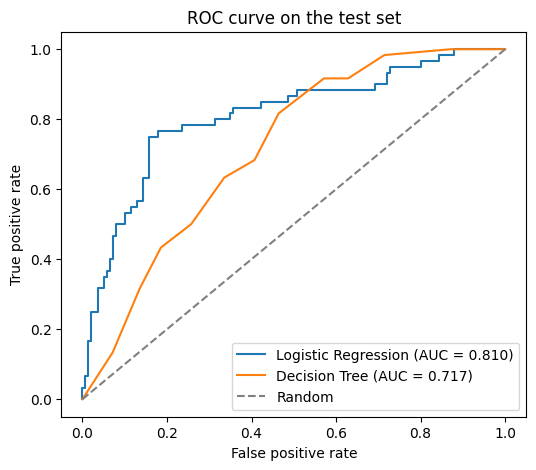

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, scores in [("Logistic Regression", pd_logit), ("Decision Tree", pd_tree)]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    ax.plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(y_test, scores):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve on the test set")
ax.legend()
plt.show()

**Interpretasi.** Kurva logistic regression berada di atas kurva tree hampir di seluruh rentang. Sebagai contoh, saat sekitar 15% nasabah lancar ikut ditandai berisiko, logistic regression sudah menangkap sekitar 75% nasabah yang benar-benar gagal bayar, sedangkan tree masih di bawah 40%. Kurva tree berbentuk tangga kasar karena tree hanya menghasilkan beberapa nilai PD berbeda (satu per ujung pohon).

### 5.2 Pohon keputusan

Gambar berikut menunjukkan 3 level teratas dari pohon yang aslinya 6 level, supaya masih terbaca. Dalam tiap kotak, `value = [a, b]` berarti a pinjaman lancar dan b pinjaman gagal bayar. Warna oranye berarti mayoritas lancar, biru berarti mayoritas gagal bayar, dan `gini` mengukur seberapa tercampur isi kotak itu (0 seragam, 0,5 campuran seimbang). Cabang kiri berlaku kalau kondisi di kotak terpenuhi (True), cabang kanan kalau tidak.

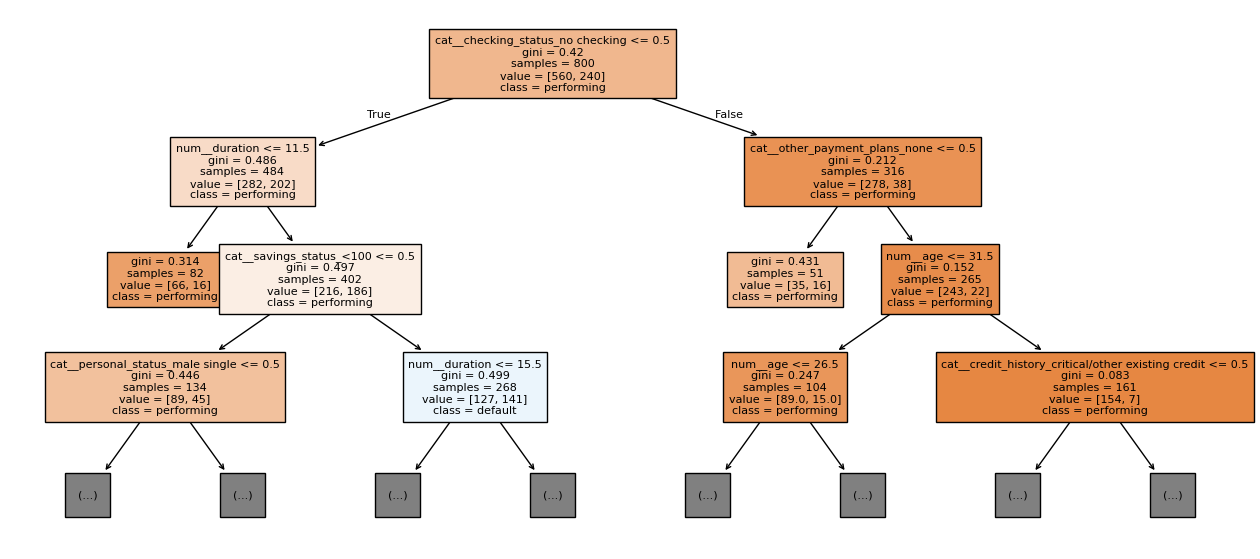

In [ ]:
tree_features = tree_model.named_steps["prep"].get_feature_names_out()
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    tree_model.named_steps["model"],
    feature_names=tree_features,
    class_names=["performing", "default"],
    max_depth=3,
    filled=True,
    fontsize=8,
    ax=ax,
)
plt.show()

**Interpretasi.**

- Pertanyaan pertama pohon: apakah nasabah tidak punya rekening giro (`checking_status = no checking`)? Cabang kiri (True pada `<= 0,5`) berarti nasabah punya rekening: 484 pinjaman dengan 202 gagal bayar, sekitar 42%. Cabang kanan berarti nasabah tidak punya rekening: 316 pinjaman dengan hanya 38 gagal bayar, sekitar 12%.
- Pada nasabah yang punya rekening, pertanyaan berikutnya adalah durasi pinjaman. Durasi 11,5 bulan atau kurang: sekitar 20% gagal bayar (16 dari 82). Lebih lama dari itu: sekitar 46% (186 dari 402).
- Pada nasabah tanpa rekening, pertanyaan berikutnya adalah ada atau tidaknya rencana cicilan lain. Yang tidak punya cicilan lain hanya sekitar 8% gagal bayar (22 dari 265), sedangkan yang punya sekitar 31% (16 dari 51).

Pola ini adalah hubungan di data, bukan sebab-akibat. Saya tidak akan menyimpulkan bahwa "tidak punya rekening membuat nasabah lebih patuh"; yang bisa dikatakan hanya bahwa variabel itu adalah pemisah terkuat yang ditemukan pohon di data ini.

## 6. Cek kalibrasi

AUC hanya menilai urutan. Untuk menghitung Expected Loss, nilai PD-nya sendiri harus mendekati kenyataan. Cara mengeceknya: urutkan 200 nasabah uji dari PD terendah ke tertinggi, bagi menjadi 5 kelompok sama besar (40 nasabah per kelompok, kelompok 1 paling aman), lalu bandingkan rata-rata PD prediksi dengan persentase yang benar-benar gagal bayar di tiap kelompok.

In [ ]:
def assign_buckets(y_true, pd_hat, n_buckets=5):
    """Rank loans by predicted PD and cut them into equal-sized buckets (1 = lowest PD)."""
    loans = pd.DataFrame({"pd": np.asarray(pd_hat), "default": np.asarray(y_true)})
    loans["bucket"] = pd.qcut(loans["pd"].rank(method="first"), n_buckets, labels=False) + 1
    return loans


def risk_bucket_table(y_true, pd_hat, n_buckets=5):
    loans = assign_buckets(y_true, pd_hat, n_buckets)
    return loans.groupby("bucket").agg(
        loans=("default", "size"),
        avg_predicted_pd=("pd", "mean"),
        observed_default_rate=("default", "mean"),
    ).round(3)


# The 3 lowest and the 3 highest predicted PDs, with the bucket each one lands in
sorted_loans = assign_buckets(y_test, pd_logit).sort_values("pd")
pd.concat([sorted_loans.head(3), sorted_loans.tail(3)]).round(3)

,pd,default,bucket
26,0.016,0,1
142,0.032,0,1
12,0.032,0,1
39,0.830,0,5
90,0.831,1,5
37,0.835,1,5


Tabel di atas memperlihatkan proses pengelompokannya: pinjaman diurutkan dari PD terkecil, tiga pinjaman paling aman masuk kelompok 1 dan tiga paling berisiko masuk kelompok 5. Kolom `default` adalah kenyataannya (0 lancar, 1 gagal bayar). Setelah semua pinjaman punya kelompok, tinggal dihitung rata-rata PD prediksi dan persentase gagal bayar sebenarnya di tiap kelompok.

In [ ]:
print(f"Average predicted PD : {pd_logit.mean():.1%}")
print(f"Actual default rate  : {y_test.mean():.1%}")
risk_bucket_table(y_test, pd_logit)

Average predicted PD : 31.1%
Actual default rate  : 30.0%


,loans,avg_predicted_pd,observed_default_rate
bucket,,,
1,40,0.071,0.075
2,40,0.153,0.125
3,40,0.273,0.125
4,40,0.413,0.450
5,40,0.644,0.725


**Hasil.**

| Kelompok | PD prediksi | Gagal bayar sebenarnya |
|---|---|---|
| 1 (paling aman) | 7,1% | 7,5% (3 dari 40) |
| 2 | 15,3% | 12,5% (5 dari 40) |
| 3 | 27,3% | 12,5% (5 dari 40) |
| 4 | 41,3% | 45,0% (18 dari 40) |
| 5 (paling berisiko) | 64,4% | 72,5% (29 dari 40) |

**Interpretasi.**

- Secara keseluruhan, rata-rata PD prediksi (31,1%) dekat dengan default rate sebenarnya (30,0%).
- Tingkat gagal bayar sebenarnya naik dari 7,5% di kelompok 1 sampai 72,5% di kelompok 5, jadi model memisahkan risiko dengan baik. Kelompok 2 dan 3 sama-sama 12,5%, jadi kenaikannya tidak benar-benar tegas di bagian tengah.
- Kelompok 1 dan 4 sangat dekat dengan kenyataan. Di kelompok 5, model memberi 64,4% sedangkan kenyataannya 72,5%, artinya model sedikit meremehkan risiko di kelompok paling berisiko.
- Kelompok 3 meleset paling jauh: model memperkirakan sekitar 11 nasabah gagal bayar (27,3% dari 40), kenyataannya 5. Dengan hanya 40 nasabah per kelompok, satu nasabah sama dengan 2,5 poin persen, jadi sebagian selisih bisa berasal dari kebetulan. Tetapi selisih 6 nasabah cukup besar untuk dicatat, dan dengan 200 data saya tidak bisa memastikan apakah itu kebetulan atau kelemahan model di rentang risiko menengah.

**Dampaknya ke Expected Loss.** Kelompok berisiko tinggi paling menentukan nilai EL. Kalau peremehan di kelompok 5 itu sistematis, EL di bagian 7 akan sedikit terlalu rendah. Dengan data sekecil ini hal itu tidak bisa dipastikan.

## 7. Stress testing dan Expected Loss

Expected Loss dihitung dengan rumus standar kerangka Basel dan IFRS 9:

$$\text{EL} = \text{PD} \times \text{LGD} \times \text{EAD}$$

- **PD**: peluang gagal bayar dari logistic regression.
- **LGD** (Loss Given Default): persentase pinjaman yang benar-benar hilang kalau nasabah gagal bayar. Saya pakai 45% sebagai kondisi normal, nilai yang dipakai Basel foundation-IRB untuk eksposur senior tanpa jaminan.
- **EAD** (Exposure at Default): jumlah yang terutang saat gagal bayar. Saya sederhanakan menjadi `credit_amount`, tanpa memperhitungkan cicilan yang sudah dibayar.

Contoh hitungan satu pinjaman: PD 20%, LGD 45%, pinjaman 5.000 DM, maka EL = 0,2 × 0,45 × 5.000 = 450 DM. EL portofolio adalah jumlah EL semua pinjaman.

**Mengapa skenarionya saya definisikan sendiri.** Data ini tidak punya variabel makro seperti PDB, pengangguran, atau suku bunga, jadi hubungan antara kondisi ekonomi dan PD tidak bisa diestimasi. Sebagai gantinya tiap skenario ditentukan lewat asumsi yang eksplisit:

| Skenario | Geser PD (log-odds) | LGD | Pengali EAD | Perubahan fitur |
|---|---|---|---|---|
| Baseline | 0 | 45% | 1,00 | tidak ada |
| Adverse | +0,4 | 50% | 1,05 | tidak ada |
| Severe | +0,8 | 60% | 1,10 | tidak ada |
| Repayment burden | 0 | 45% | 1,00 | durasi ×1,3 dan jumlah kredit ×1,4 |

**Tentang geser PD.** Log-odds dari PD adalah ln(PD / (1 − PD)). Menambahkan angka ke log-odds berarti mengalikan odds gagal bayar: +0,4 mengalikan odds dengan sekitar 1,5 dan +0,8 dengan sekitar 2,2. Contohnya PD 20% menjadi sekitar 27% (+0,4) atau sekitar 36% (+0,8). Cara ini dipilih karena PD tetap berada di antara 0 dan 1; kalau PD dikali langsung, PD 80% bisa melewati 100%. Asumsi uniform odds ratio ini adalah simplifikasi: di krisis nyata, guncangan PD biasanya tidak seragam — nasabah dengan risiko awal tinggi bisa naik jauh lebih tajam daripada yang berisiko rendah. Tanpa data makro, saya tidak bisa mengestimasi heterogenitas ini, jadi saya memilih asumsi yang transparan dan konservatif..

**Tentang skenario Repayment Burden.** Berbeda dari tiga skenario lain, PD di sini tidak digeser manual di skala log-odds. Sebagai gantinya, dua fitur nasabah — duration (durasi pinjaman) dan credit_amount (jumlah kredit) — dikalikan faktor tertentu, lalu nasabah dinilai ulang oleh model. Jadi PD berubah lewat koefisien model, bukan lewat guncangan buatan. Skenario ini mewakili beban cicilan yang lebih berat setelah, misalnya, kenaikan suku bunga atau inflasi: pinjaman yang sama terasa lebih berat karena durasinya memanjang dan nominalnya membengkak.

In [ ]:
BASE_LGD = 0.45

scenarios = [
    {"name": "Baseline", "pd_logit_shift": 0.0, "lgd": BASE_LGD, "ead_multiplier": 1.00, "feature_shocks": {}},
    {"name": "Adverse", "pd_logit_shift": 0.4, "lgd": 0.50, "ead_multiplier": 1.05, "feature_shocks": {}},
    {"name": "Severe", "pd_logit_shift": 0.8, "lgd": 0.60, "ead_multiplier": 1.10, "feature_shocks": {}},
    {
        "name": "Repayment burden",
        "pd_logit_shift": 0.0,
        "lgd": BASE_LGD,
        "ead_multiplier": 1.00,
        "feature_shocks": {"duration": 1.30, "credit_amount": 1.40},
    },
]


def shift_pd(pd_hat, logit_shift):
    """Shift PD by a constant on the log-odds scale and convert back to a probability."""
    pd_hat = np.clip(pd_hat, 1e-6, 1 - 1e-6)
    log_odds = np.log(pd_hat / (1 - pd_hat))
    return 1 / (1 + np.exp(-(log_odds + logit_shift)))


def apply_scenario(model, X, scenario):
    """Loan-level PD, EAD and expected loss under one scenario."""
    shocked = X.copy()
    for column, multiplier in scenario["feature_shocks"].items():
        shocked[column] = shocked[column] * multiplier

    pd_hat = shift_pd(model.predict_proba(shocked)[:, 1], scenario["pd_logit_shift"])
    ead = shocked["credit_amount"].to_numpy() * scenario["ead_multiplier"]
    expected_loss = pd_hat * scenario["lgd"] * ead
    return pd_hat, ead, expected_loss


def run_scenario(model, X, scenario):
    """Portfolio-level summary of one scenario."""
    pd_hat, ead, expected_loss = apply_scenario(model, X, scenario)

    return {
        "Scenario": scenario["name"],
        "Avg PD": pd_hat.mean(),
        "LGD": scenario["lgd"],
        "Total EAD (DM)": ead.sum(),
        "Expected Loss (DM)": expected_loss.sum(),
        "EL / EAD": expected_loss.sum() / ead.sum(),
    }

Fungsi `apply_scenario` bekerja dalam lima langkah: menyalin data uji, menerapkan perubahan fitur (kalau ada), memprediksi PD dan menggesernya, menghitung EAD, lalu menghitung EL per pinjaman. `run_scenario` merangkum hasilnya untuk seluruh portofolio. Data aslinya tidak diubah karena yang dimodifikasi adalah salinannya.

Sebelum menjalankan semua skenario, tiga tabel berikut memperlihatkan apa yang terjadi pada data di dalam proses itu.

**(a) Geser PD di skala log-odds.** Beberapa PD contoh dikonversi ke log-odds, digeser, lalu dikonversi balik menjadi PD.

In [ ]:
demo_pd = np.array([0.05, 0.20, 0.50, 0.80])
shift_demo = pd.DataFrame({
    "PD baseline": demo_pd,
    "log-odds": np.log(demo_pd / (1 - demo_pd)),
    "PD after +0.4": shift_pd(demo_pd, 0.4),
    "PD after +0.8": shift_pd(demo_pd, 0.8),
}).round(3)
shift_demo

,PD baseline,log-odds,PD after +0.4,PD after +0.8
0,0.05,-2.944,0.073,0.105
1,0.20,-1.386,0.272,0.357
2,0.50,0.000,0.599,0.690
3,0.80,1.386,0.856,0.899


Odds gagal bayar dikalikan faktor yang sama untuk semua nasabah (sekitar 1,5 pada +0,4 dan 2,2 pada +0,8), tetapi PD yang sudah tinggi naik lebih sedikit dalam poin persentase dan tidak pernah melewati 1. Itu alasan geser dilakukan di skala log-odds, bukan dengan mengalikan PD langsung.

**(b) Perubahan fitur pada skenario Repayment burden**, untuk lima pinjaman uji pertama.

In [ ]:
burden = next(s for s in scenarios if s["name"] == "Repayment burden")

before = X_test[["duration", "credit_amount"]].head(5)
after = before.copy()
for column, multiplier in burden["feature_shocks"].items():
    after[column] = after[column] * multiplier

pd.concat({"before": before, "after": after}, axis=1)

before                  after              
    duration credit_amount duration credit_amount
30        18          1913     23.4        2678.2
128       12          1860     15.6        2604.0
289       24          1024     31.2        1433.6
216       18          3104     23.4        4345.6
966       27          2520     35.1        3528.0

Durasi dikali 1,3 dan jumlah kredit dikali 1,4. Perubahan ini hanya terjadi di salinan data. Setelah itu nasabah dinilai ulang oleh model, jadi PD-nya berubah mengikuti koefisien model.

**(c) Satu pinjaman, empat skenario.** PD, EAD, dan EL untuk lima pinjaman uji pertama di tiap skenario.

In [ ]:
sample_ids = X_test.index[:5]
loan_level = {}
for scenario in scenarios:
    pd_s, ead_s, el_s = apply_scenario(logit_model, X_test.loc[sample_ids], scenario)
    loan_level[scenario["name"]] = pd.DataFrame(
        {"PD": pd_s, "EAD": ead_s, "EL": el_s}, index=sample_ids
    )

pd.concat(loan_level, axis=1).round(2)

Baseline                 Adverse                  Severe                   \
          PD     EAD      EL      PD      EAD      EL     PD     EAD       EL   
30      0.31  1913.0  268.76    0.40  2008.65  405.50   0.50  2104.3   634.49   
128     0.15  1860.0  123.70    0.21  1953.00  200.71   0.28  2046.0   341.86   
289     0.56  1024.0  256.90    0.65  1075.20  350.91   0.74  1126.4   498.18   
216     0.44  3104.0  615.37    0.54  3259.20  880.29   0.64  3414.4  1304.39   
966     0.18  2520.0  208.62    0.25  2646.00  332.97   0.33  2772.0   555.68   

    Repayment burden                  
                  PD     EAD      EL  
30              0.36  2678.2  431.85  
128             0.17  2604.0  197.81  
289             0.61  1433.6  394.81  
216             0.50  4345.6  981.97  
966             0.23  3528.0  370.12

Bacalah satu baris dari kiri ke kanan: PD dan EAD berubah sesuai skenario, dan EL adalah hasil PD × LGD × EAD dengan LGD skenario itu (45%, 50%, 60%, dan 45%). Perhitungan yang sama dilakukan untuk seluruh 200 pinjaman uji, lalu EL-nya dijumlahkan menjadi total EL pada tabel hasil di bawah.

In [ ]:
results = pd.DataFrame([run_scenario(logit_model, X_test, s) for s in scenarios]).set_index("Scenario")
baseline_el = results.loc["Baseline", "Expected Loss (DM)"]
results["EL change vs baseline"] = results["Expected Loss (DM)"] / baseline_el - 1

results.style.format({
    "Avg PD": "{:.1%}", "LGD": "{:.0%}", "Total EAD (DM)": "{:,.0f}",
    "Expected Loss (DM)": "{:,.0f}", "EL / EAD": "{:.2%}", "EL change vs baseline": "{:+.1%}",
})

,Avg PD,LGD,Total EAD (DM),Expected Loss (DM),EL / EAD,EL change vs baseline
Scenario,,,,,,
Baseline,31.1%,45%,"719,585","123,156",17.11%,+0.0%
Adverse,38.2%,50%,"755,564","171,900",22.75%,+39.6%
Severe,45.7%,60%,"791,544","252,305",31.88%,+104.9%
Repayment burden,36.4%,45%,"1,007,419","210,901",20.93%,+71.2%


**Hasil.**

| Skenario | Rata-rata PD | Total EAD (DM) | EL (DM) | EL / EAD | Perubahan EL |
|---|---|---|---|---|---|
| Baseline | 31,1% | 719.585 | 123.156 | 17,11% | - |
| Adverse | 38,2% | 755.564 | 171.900 | 22,75% | +39,6% |
| Severe | 45,7% | 791.544 | 252.305 | 31,88% | +104,9% |
| Repayment burden | 36,4% | 1.007.419 | 210.901 | 20,93% | +71,2% |

**Interpretasi.**

- Pada skenario Severe, EL naik lebih dari dua kali lipat (+104,9%). Penyebabnya tiga komponen naik bersamaan: rata-rata PD naik sekitar 1,47 kali (31,1% ke 45,7%), LGD naik 1,33 kali (45% ke 60%), dan EAD naik 1,10 kali. Karena EL adalah perkalian, kenaikan-kenaikan itu saling melipatgandakan: 1,47 × 1,33 × 1,10 kira-kira 2,2, mendekati kenaikan yang terlihat (sedikit lebih rendah karena EL dihitung per pinjaman dan pinjaman besar punya bobot lebih).
- Skenario Adverse mengikuti pola yang sama dengan ukuran lebih kecil: PD sekitar 1,23 kali, LGD 1,11 kali, EAD 1,05 kali, EL naik 39,6%.
- Pada Repayment burden, kenaikan EL sebagian besar datang dari EAD, bukan dari PD. Total EAD naik sekitar 40% (dari 719.585 ke 1.007.419 DM) karena jumlah kredit dikali 1,4, sedangkan rata-rata PD naik dari 31,1% ke 36,4%.
- Karena besarnya guncangan di tiap skenario saya yang menentukan, urutan EL antar skenario (misalnya Repayment burden lebih tinggi dari Adverse) tidak membuktikan bahwa satu jenis guncangan lebih berbahaya dari yang lain. Yang ditunjukkan hanya seberapa sensitif EL terhadap asumsi yang saya masukkan.
- EL / EAD baseline sebesar 17% sangat tinggi dibanding portofolio bank nyata. Itu konsekuensi default rate 30% di data ini.

Untuk melihat apakah kenaikan EL memang berlipat, tabel berikut membagi tiap komponen skenario dengan nilai baseline, lalu mengalikan ketiganya dan membandingkannya dengan kenaikan EL yang sebenarnya.

In [ ]:
base = results.loc["Baseline"]
multipliers = pd.DataFrame({
    "PD x": results["Avg PD"] / base["Avg PD"],
    "LGD x": results["LGD"] / base["LGD"],
    "EAD x": results["Total EAD (DM)"] / base["Total EAD (DM)"],
})
multipliers["PD x LGD x EAD"] = multipliers.prod(axis=1)
multipliers["EL x (actual)"] = results["Expected Loss (DM)"] / base["Expected Loss (DM)"]
multipliers.round(2)

,PD x,LGD x,EAD x,PD x LGD x EAD,EL x (actual)
Scenario,,,,,
Baseline,1.00,1.00,1.00,1.00,1.00
Adverse,1.23,1.11,1.05,1.43,1.40
Severe,1.47,1.33,1.10,2.16,2.05
Repayment burden,1.17,1.00,1.40,1.64,1.71


Hasil kali ketiga pengali berada dekat dengan kenaikan EL yang sebenarnya, misalnya pada Severe sekitar 2,2 dibanding 2,05. Itu menunjukkan EL naik karena tiga komponen saling berlipat. Selisih kecilnya wajar: tabel ini memakai rata-rata PD, sedangkan EL dihitung per pinjaman sehingga pinjaman besar punya bobot lebih. Pada Repayment burden, pengali EAD (1,40) jelas menjadi komponen yang paling besar.

Grafik berikut meringkas EL tiap skenario.

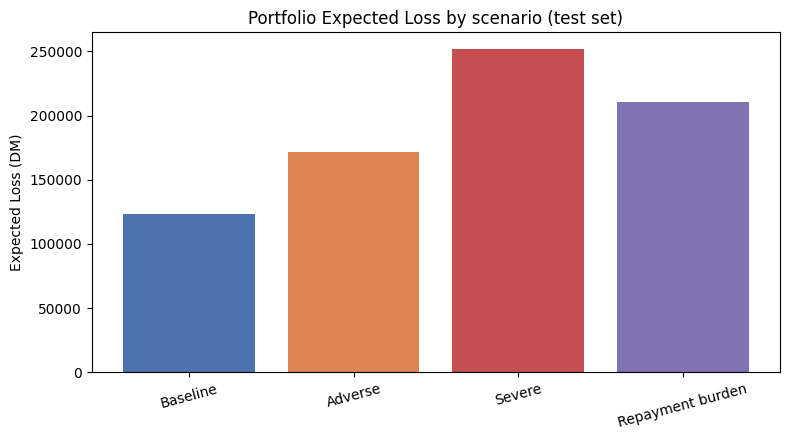

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(results.index, results["Expected Loss (DM)"], color=["#4c72b0", "#dd8452", "#c44e52", "#8172b3"])
ax.set_ylabel("Expected Loss (DM)")
ax.set_title("Portfolio Expected Loss by scenario (test set)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 7.1 Pengecekan wajar atau tidak

Sebagai pengecekan kasar, EL baseline saya bandingkan dengan kerugian yang benar-benar terjadi di data uji, yaitu jumlah dari (gagal bayar aktual × LGD × EAD). Kalau kedua angka berbeda orde besarnya, ada yang salah di PD atau perhitungannya.

In [ ]:
realised_loss = (y_test.to_numpy() * BASE_LGD * X_test["credit_amount"].to_numpy()).sum()
gap = baseline_el / realised_loss - 1

print(f"Baseline expected loss : DM {baseline_el:,.0f}")
print(f"Realised loss (test)   : DM {realised_loss:,.0f}")
print(f"Difference             : {gap:+.1%}")

Baseline expected loss : DM 123,156
Realised loss (test)   : DM 126,000
Difference             : -2.3%


**Cara membaca.** Kedua angka seharusnya berada pada orde besar yang sama. Tidak ada ambang baku untuk selisih yang dianggap "cukup dekat". Karena data uji hanya 200 pinjaman dan beberapa pinjaman besar bisa menggeser total cukup banyak, selisih beberapa persen sampai belasan persen masih wajar. Catatan penting: pengecekan ini memakai LGD yang sama (45%) di kedua sisi, jadi hanya menguji PD dan EAD, bukan LGD.

**Satu catatan istilah.** EL adalah kerugian rata-rata yang diharapkan, dan dalam praktik ditutup lewat pencadangan (provisi, atau ECL di IFRS 9). Kerugian di atas rata-rata (unexpected loss) ditutup oleh modal. Notebook ini hanya menghitung EL, tidak menghitung kebutuhan modal, jadi kenaikan EL di skenario stres tidak bisa langsung diterjemahkan menjadi "kebutuhan modal naik dua kali".

## 8. Keterbatasan dan kesimpulan

### Keterbatasan

1. **Data lama dan kecil.** 1.000 pinjaman dari 1990-an dalam DM tidak mewakili kondisi sekarang, termasuk di Indonesia.
2. **Test set kecil.** Hanya 200 pinjaman (60 gagal bayar) dan hanya satu kali pembagian data, jadi semua angka validasi, terutama KS dan tabel kelompok risiko, punya ketidakpastian yang tidak kecil.
3. **Skenario stres berupa asumsi.** Tidak ada hubungan PD dengan variabel makro yang diestimasi dari data. Dengan data bank nyata, langkah berikutnya adalah membuat satellite model yang menghubungkan PD dengan variabel seperti pertumbuhan PDB, pengangguran, dan suku bunga.
4. **LGD dan EAD disederhanakan.** Keduanya diperlakukan sebagai konstanta (atau kelipatan konstanta), tanpa model tersendiri, tanpa amortisasi, dan tanpa credit conversion factor.
5. **Horizon PD tidak didefinisikan.** Target di data ini adalah gagal bayar selama masa pinjaman, bukan PD 12 bulan atau lifetime seperti yang dibedakan di IFRS 9.
6. **Grid pencarian parameter tree berada di batas.** Parameter terbaik tree jatuh di nilai terbesar yang dicoba, jadi tree mungkin belum dituning secara optimal.
7. **Tidak ada uji stabilitas.** Data tidak punya dimensi waktu, jadi model tidak bisa diuji stabilitasnya (misalnya dengan PSI atau out-of-time testing).

### Kesimpulan

1. Logistic regression lebih baik dari decision tree pada data uji di semua ukuran (AUC 0,810 dibanding 0,717; Gini 0,619 dibanding 0,434; KS 0,593 dibanding 0,352; Brier 0,155 dibanding 0,197), dan hasil cross-validation menunjukkan arah yang sama.
2. Rata-rata PD prediksi (31,1%) dekat dengan default rate sebenarnya (30,0%) dan risiko naik konsisten dari kelompok 1 sampai 5, tetapi di tingkat kelompok ada selisih, terutama kelompok 3 (terlalu tinggi) dan kelompok 5 (terlalu rendah), yang dengan 200 data belum bisa dipastikan sebagai kebetulan atau bukan.
3. Pada skenario Severe, EL naik lebih dari dua kali lipat (+104,9%) karena PD, LGD, dan EAD naik bersamaan dan efeknya berlipat. Besarnya kenaikan bergantung pada asumsi guncangan yang saya pilih, bukan hasil estimasi dari data makro.

### Pengembangan lanjutan

- Memperluas grid parameter tree dan menambahkan model berbasis ensemble (misalnya gradient boosting) sebagai pembanding.
- Memakai k-fold cross-validation untuk seluruh tahap validasi, bukan hanya satu test set, supaya ketidakpastian angka lebih terlihat.
- Mengganti skenario manual dengan satellite model berbasis data makro Indonesia, kalau ada data PD historis yang bisa dipakai.
- Memodelkan LGD dan EAD secara terpisah.